# Preprocesamiento de imagenes con OpenCV

La imagen real se descarga directamente desde Internet y se usa en cada transformacion.

In [ ]:
!pip -q install opencv-python-headless

import cv2
import matplotlib.pyplot as plt
import numpy as np
import urllib.request

## 1. Descargar y mostrar la imagen original en RGB

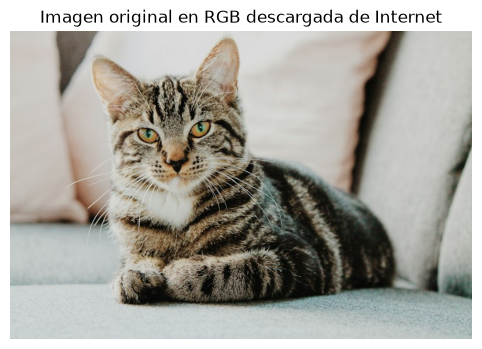

In [15]:
url = "https://images.unsplash.com/photo-1518791841217-8f162f1e1131?w=800&q=80"
solicitud = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(solicitud, timeout=30) as respuesta:
    datos = respuesta.read()

imagen_bgr = cv2.imdecode(np.frombuffer(datos, np.uint8), cv2.IMREAD_COLOR)
if imagen_bgr is None:
    raise ValueError("No se pudo descargar o leer la imagen desde Internet.")

imagen_rgb = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 4))
plt.imshow(imagen_rgb)
plt.title("Imagen original en RGB descargada de Internet")
plt.axis("off")
plt.show()

## 2. Redimensionar a 64 x 64 y convertir a gris y HSV

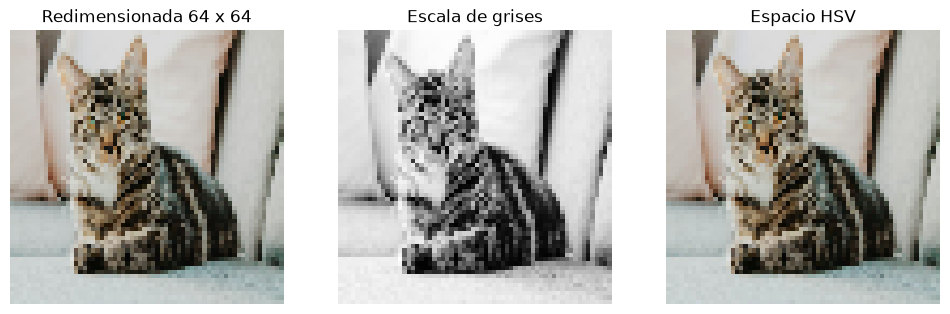

In [16]:
imagen_64 = cv2.resize(imagen_rgb, (64, 64))
gris = cv2.cvtColor(imagen_64, cv2.COLOR_RGB2GRAY)
hsv = cv2.cvtColor(imagen_64, cv2.COLOR_RGB2HSV)
hsv_visual = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(imagen_64)
ax[0].set_title("Redimensionada 64 x 64")
ax[1].imshow(gris, cmap="gray")
ax[1].set_title("Escala de grises")
ax[2].imshow(hsv_visual)
ax[2].set_title("Espacio HSV")
for eje in ax:
    eje.axis("off")
plt.show()

## 3. Brillo, contraste y deteccion de bordes

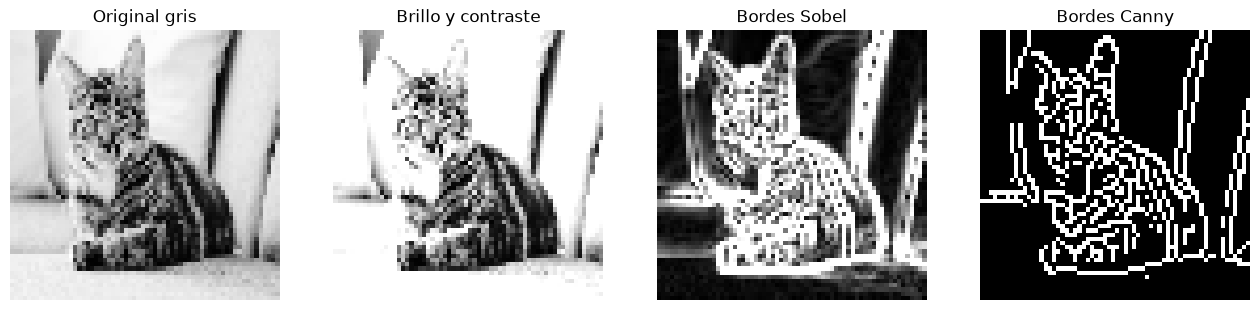

In [17]:
gris_ajustado = cv2.convertScaleAbs(gris, alpha=1.3, beta=25)
sobel_x = cv2.Sobel(gris, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gris, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))
canny = cv2.Canny(gris, 100, 200)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
resultados = [(gris, "Original gris"), (gris_ajustado, "Brillo y contraste"), (sobel, "Bordes Sobel"), (canny, "Bordes Canny")]
for eje, (resultado, titulo) in zip(ax, resultados):
    eje.imshow(resultado, cmap="gray")
    eje.set_title(titulo)
    eje.axis("off")
plt.show()

## 4. Data augmentation

Se aplican volteo vertical, rotacion de 45 grados, desplazamiento horizontal y vertical, y zoom.

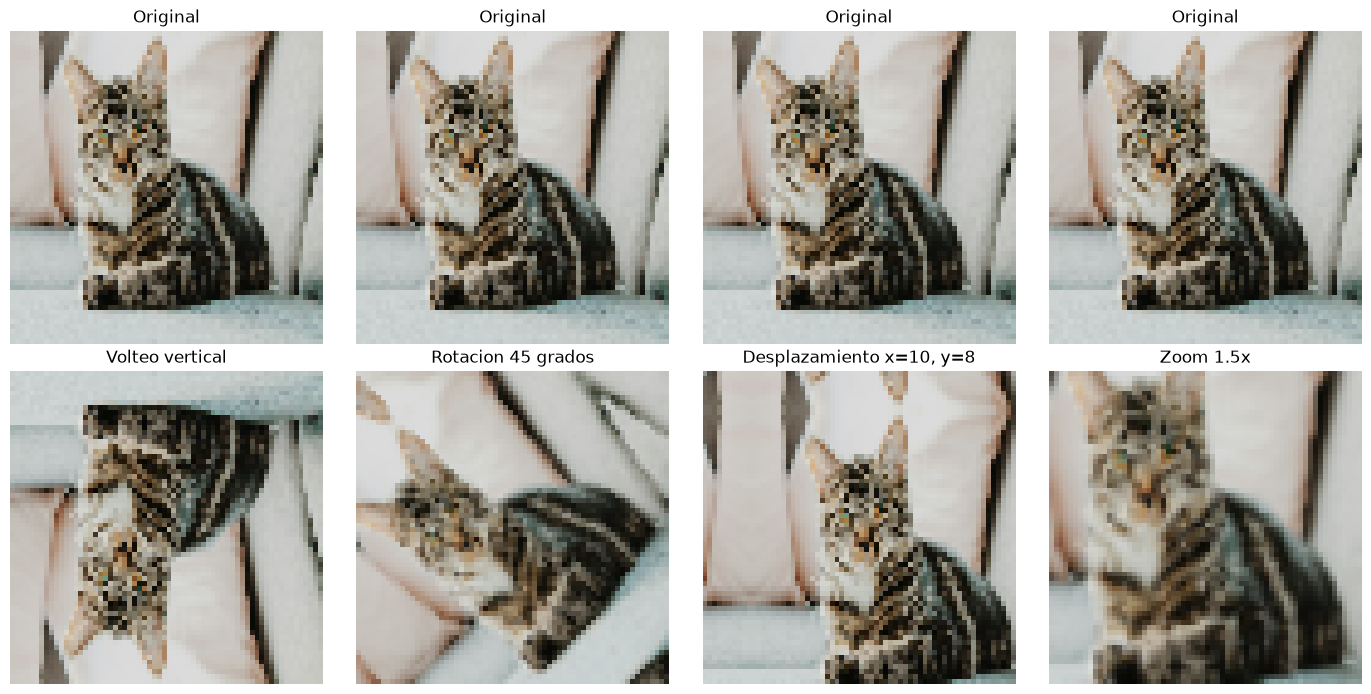

In [18]:
alto, ancho = imagen_64.shape[:2]
volteo = cv2.flip(imagen_64, 0)

matriz_rotacion = cv2.getRotationMatrix2D((ancho / 2, alto / 2), 45, 1)
rotacion = cv2.warpAffine(imagen_64, matriz_rotacion, (ancho, alto), borderMode=cv2.BORDER_REFLECT)

matriz_movimiento = np.float32([[1, 0, 10], [0, 1, 8]])
desplazamiento = cv2.warpAffine(imagen_64, matriz_movimiento, (ancho, alto), borderMode=cv2.BORDER_REFLECT)

recorte = imagen_64[8:56, 8:56]
zoom = cv2.resize(recorte, (64, 64))

aumentos = [(volteo, "Volteo vertical"), (rotacion, "Rotacion 45 grados"), (desplazamiento, "Desplazamiento x=10, y=8"), (zoom, "Zoom 1.5x")]
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for i, (resultado, titulo) in enumerate(aumentos):
    ax[0, i].imshow(imagen_64)
    ax[0, i].set_title("Original")
    ax[1, i].imshow(resultado)
    ax[1, i].set_title(titulo)
    ax[0, i].axis("off")
    ax[1, i].axis("off")
plt.tight_layout()
plt.show()